# 1. Dataset EDA

Exploratory analysis of the Kaggle Waste Classification Data set used to train the KTSustainability classifier.

It answers: how many images are there per class, what do they look like, are any broken or repeated, and does the published test set look like the training set?

Set the `WASTE_DATA_DIR` environment variable if your dataset is not at `~/Downloads/archive/DATASET`.

In [1]:
import hashlib
import os
import sys
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "eda"))

import plotstyle as ps
from waste_classifier.data import CLASS_NAMES, build_splits, list_images, resolve_data_dir

ps.apply()
DATA_DIR = resolve_data_dir(os.environ.get("WASTE_DATA_DIR", "~/Downloads/archive/DATASET"))
CACHE = ROOT / "outputs" / "eda_image_stats.csv"
print("Dataset:", DATA_DIR)

Dataset: /sessions/rcw-01gjvurr6gyycytovrthvx2g/mnt/archive/DATASET


## Scan every image

One pass over all files records the size, real file format, a content hash (to find exact duplicates), and two simple appearance measures taken from a 64x64 thumbnail:

- **brightness**: mean pixel value, 0 (black) to 255 (white)
- **white background share**: fraction of pixels that are near-white, a rough marker for clean product shots

The result is cached in `outputs/eda_image_stats.csv`, so reruns are instant.

In [2]:
def image_stats(item):
    path, split, label = item
    raw = Path(path).read_bytes()
    row = {"path": str(Path(path).relative_to(DATA_DIR)), "split": split,
           "label": CLASS_NAMES[label], "bytes": len(raw),
           "md5": hashlib.md5(raw).hexdigest(), "error": ""}
    try:
        with Image.open(path) as im:
            row.update(width=im.width, height=im.height, format=im.format, mode=im.mode)
            thumb = np.asarray(im.convert("RGB").resize((64, 64)), dtype=np.float32)
        row["brightness"] = thumb.mean()
        row["white_share"] = (thumb.min(axis=2) > 235).mean()
        row["red"], row["green"], row["blue"] = thumb.reshape(-1, 3).mean(axis=0)
    except Exception as exc:  # a file that cannot be decoded
        row["error"] = repr(exc)[:80]
    return row


if CACHE.exists():
    df = pd.read_csv(CACHE, keep_default_na=False, na_values=[""]).fillna({"error": ""})
else:
    items = []
    for split in ("TRAIN", "TEST"):
        paths, labels = list_images(DATA_DIR / split)
        items += [(p, split, l) for p, l in zip(paths, labels)]
    with ThreadPoolExecutor(8) as pool:
        df = pd.DataFrame(pool.map(image_stats, items))
    CACHE.parent.mkdir(exist_ok=True)
    df.to_csv(CACHE, index=False)

print(f"{len(df):,} images scanned, {(df.error != '').sum()} unreadable")
df.head()

25,077 images scanned, 0 unreadable


,path,split,label,bytes,md5,error,width,height,format,mode,brightness,white_share,red,green,blue
0,TRAIN/O/O_1.jpg,TRAIN,Organic,15259,d5b846b73a5d4c07ff0c165126ff04fe,,208,242,JPEG,RGB,186.417720,0.411621,233.95459,171.128660,154.16992
1,TRAIN/O/O_10.jpg,TRAIN,Organic,9760,d9023de38c99cba1a0c2f7a8163bf7f5,,275,183,JPEG,RGB,196.590820,0.607178,224.36719,182.182860,183.22241
2,TRAIN/O/O_100.jpg,TRAIN,Organic,6250,d8ac8d103b25f2407bcdc8ef30025816,,275,183,JPEG,RGB,194.697830,0.558594,187.28540,226.269040,170.53906
3,TRAIN/O/O_1000.jpg,TRAIN,Organic,10033,1afa743cc4aa8b3b8f8b373b6f3fddb5,,242,209,JPEG,RGB,208.704420,0.497559,245.16724,206.855960,174.09009
4,TRAIN/O/O_10000.jpg,TRAIN,Organic,4992,dadeef0904dbcd47e965e4351b3ae5e5,,271,186,JPEG,RGB,55.124756,0.000000,55.73291,63.055176,46.58618


## Class balance

label,Organic,Recyclable,total,organic_share
split,,,,
TRAIN,12565,9999,22564,0.557
TEST,1401,1112,2513,0.558


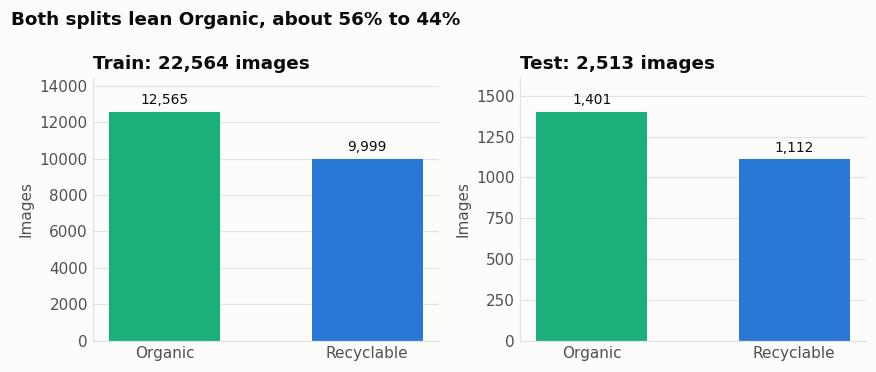

In [3]:
counts = df.groupby(["split", "label"]).size().unstack().loc[["TRAIN", "TEST"]]
display(counts.assign(total=counts.sum(axis=1),
                      organic_share=(counts["Organic"] / counts.sum(axis=1)).round(3)))

fig, axes = plt.subplots(1, 2, figsize=(8, 3.4), gridspec_kw={"width_ratios": [1, 1]})
for ax, split in zip(axes, ["TRAIN", "TEST"]):
    bars = ax.bar(CLASS_NAMES, counts.loc[split, CLASS_NAMES], width=0.55,
                  color=[ps.CLASS_COLORS[c] for c in CLASS_NAMES])
    ps.label_bars(ax, bars)
    ax.set_title(f"{split.title()}: {counts.loc[split].sum():,} images")
    ax.set_ylabel("Images")
    ax.margins(y=0.15)
fig.suptitle("Both splits lean Organic, about 56% to 44%", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
ps.save(fig, "01_class_balance.png")

## File health: formats and unreadable files

Every file is named `.jpg`, but the scan reads the real format from the file contents.

In [4]:
display(df.groupby(["format", "mode"]).size().rename("images").to_frame())
print("Unreadable files:", (df.error != "").sum())

,,images
format,mode,
JPEG,RGB,24705
PNG,P,372


Unreadable files: 0


## Duplicates and train/test leakage

Images with the same content hash are byte-for-byte copies. Copies that sit in both TRAIN and TEST are the serious kind: a model can memorise them and score better on TEST than it deserves.

326 images appear more than once (652 files)
  in both TRAIN and TEST: 285
  under both labels:      1


,training images removed
repeated_in_train,40
also_in_test,285
conflicting_label,2


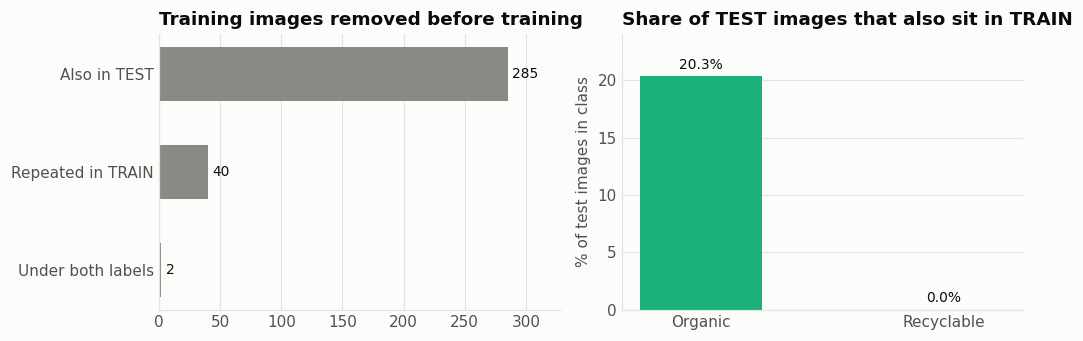

In [5]:
groups = df.groupby("md5").agg(copies=("path", "size"), splits=("split", "nunique"),
                               labels=("label", "nunique"))
dupes = groups[groups.copies > 1]
print(f"{len(dupes)} images appear more than once ({dupes.copies.sum()} files)")
print(f"  in both TRAIN and TEST: {(dupes.splits > 1).sum()}")
print(f"  under both labels:      {(dupes.labels > 1).sum()}")

splits = build_splits(DATA_DIR)
dropped = splits.report["dropped_from_train"]
display(pd.Series(dropped, name="training images removed").to_frame())

leak_by_class = (df[df.md5.isin(dupes[dupes.splits > 1].index) & (df.split == "TEST")]
                 .groupby("label").size())
test_sizes = df[df.split == "TEST"].groupby("label").size()

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2))
labels = ["Also in TEST", "Repeated in TRAIN", "Under both labels"]
values = [dropped.get("also_in_test", 0), dropped.get("repeated_in_train", 0),
          dropped.get("conflicting_label", 0)]
bars = axes[0].barh(labels[::-1], values[::-1], color=ps.TRAIN, height=0.55)
ps.label_bars(axes[0], bars, horizontal=True)
axes[0].set_title("Training images removed before training")
axes[0].grid(axis="x"); axes[0].grid(axis="y", visible=False); axes[0].margins(x=0.15)

share = (leak_by_class / test_sizes * 100).reindex(CLASS_NAMES).fillna(0)
bars = axes[1].bar(CLASS_NAMES, share, width=0.5, color=[ps.CLASS_COLORS[c] for c in CLASS_NAMES])
ps.label_bars(axes[1], bars, fmt="{:.1f}%")
axes[1].set_title("Share of TEST images that also sit in TRAIN")
axes[1].set_ylabel("% of test images in class"); axes[1].margins(y=0.18)
fig.tight_layout()
ps.save(fig, "02_duplicates_and_leakage.png")

## Image dimensions

,width,height,aspect,bytes
min,51.0,69.0,0.1,790.0
25%,225.0,183.0,1.0,5664.0
50%,259.0,194.0,1.3,8464.0
75%,275.0,225.0,1.5,11527.0
max,1460.0,1500.0,8.7,477721.0


0.7% of images are wider than 400 px (clipped into the last bin)


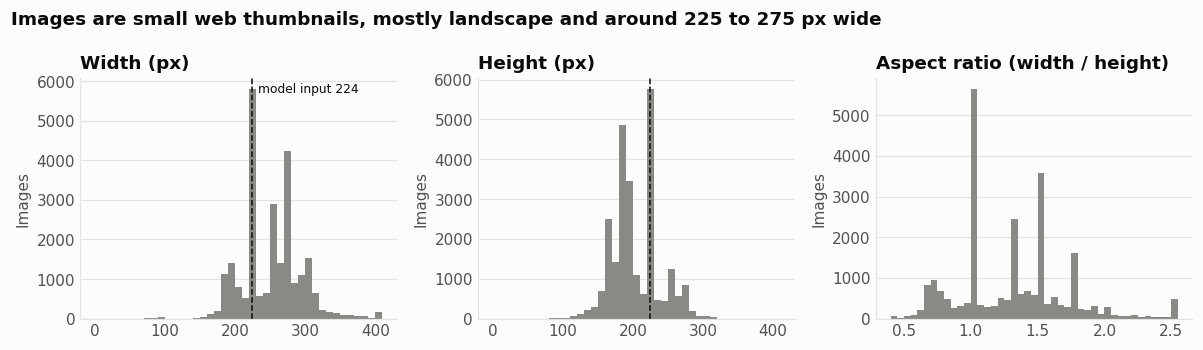

In [6]:
ok = df[df.error == ""].copy()
ok["aspect"] = ok.width / ok.height
display(ok[["width", "height", "aspect", "bytes"]].describe().round(1).loc[["min", "25%", "50%", "75%", "max"]])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, column, title, bins in [
    (axes[0], "width", "Width (px)", np.arange(0, 420, 10)),
    (axes[1], "height", "Height (px)", np.arange(0, 420, 10)),
    (axes[2], "aspect", "Aspect ratio (width / height)", np.arange(0.4, 2.6, 0.05)),
]:
    ax.hist(ok[column].clip(bins[0], bins[-1]), bins=bins, color=ps.TRAIN)
    ax.set_title(title); ax.set_ylabel("Images")
axes[0].axvline(224, color=ps.INK, lw=1, ls="--"); axes[0].annotate("model input 224", (224, axes[0].get_ylim()[1]), xytext=(4, -10), textcoords="offset points", fontsize=8)
axes[1].axvline(224, color=ps.INK, lw=1, ls="--")
fig.suptitle("Images are small web thumbnails, mostly landscape and around 225 to 275 px wide", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
ps.save(fig, "03_image_dimensions.png")
print(f"{(ok.width > 400).mean():.1%} of images are wider than 400 px (clipped into the last bin)")

## Does TEST look like TRAIN?

If the test images came from the same pool as the training images, their brightness and background should be distributed the same way within each class. Each panel overlays the two splits for one class.

median_brightness  median_white_share  \
label      split                                          
Organic    TEST              133.26                0.01   
           TRAIN             141.01                0.01   
Recyclable TEST              184.90                0.12   
           TRAIN             189.27                0.25   

                  mostly_white_background  
label      split                           
Organic    TEST                      0.09  
           TRAIN                     0.15  
Recyclable TEST                      0.23  
           TRAIN                     0.33

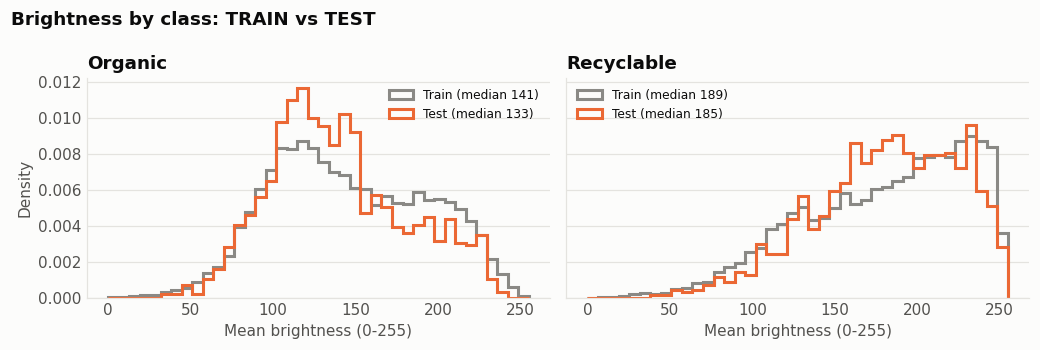

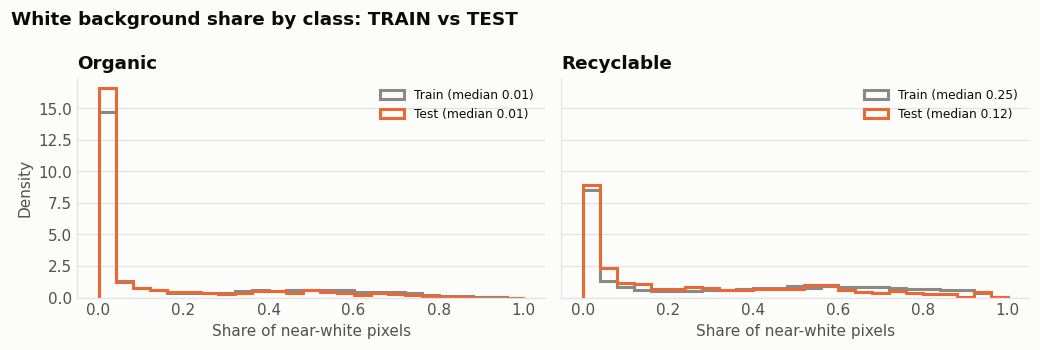

In [7]:
def compare_splits(column, bins, xlabel, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2), sharey=True)
    for ax, name in zip(axes, CLASS_NAMES):
        for split in ("TRAIN", "TEST"):
            values = ok[(ok.label == name) & (ok.split == split)][column]
            ax.hist(values, bins=bins, density=True, histtype="step", lw=2,
                    color=ps.SPLIT_COLORS[split], label=f"{split.title()} (median {values.median():.2f})"
                    if values.median() < 10 else f"{split.title()} (median {values.median():.0f})")
        ax.set_title(name); ax.set_xlabel(xlabel); ax.legend(fontsize=8)
    axes[0].set_ylabel("Density")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    ps.save(fig, filename)

compare_splits("brightness", np.linspace(0, 255, 41), "Mean brightness (0-255)",
               "Brightness by class: TRAIN vs TEST", "04_brightness_train_vs_test.png")
compare_splits("white_share", np.linspace(0, 1, 26), "Share of near-white pixels",
               "White background share by class: TRAIN vs TEST", "05_white_background_train_vs_test.png")

display(ok.assign(mostly_white=ok.white_share > 0.5).groupby(["label", "split"])
        .agg(median_brightness=("brightness", "median"), median_white_share=("white_share", "median"),
             mostly_white_background=("mostly_white", "mean")).round(2))

## What the images look like

A random sample from each class and split. Recyclable images are mostly isolated objects on plain backgrounds; Organic images are mostly food and plants filling the frame.

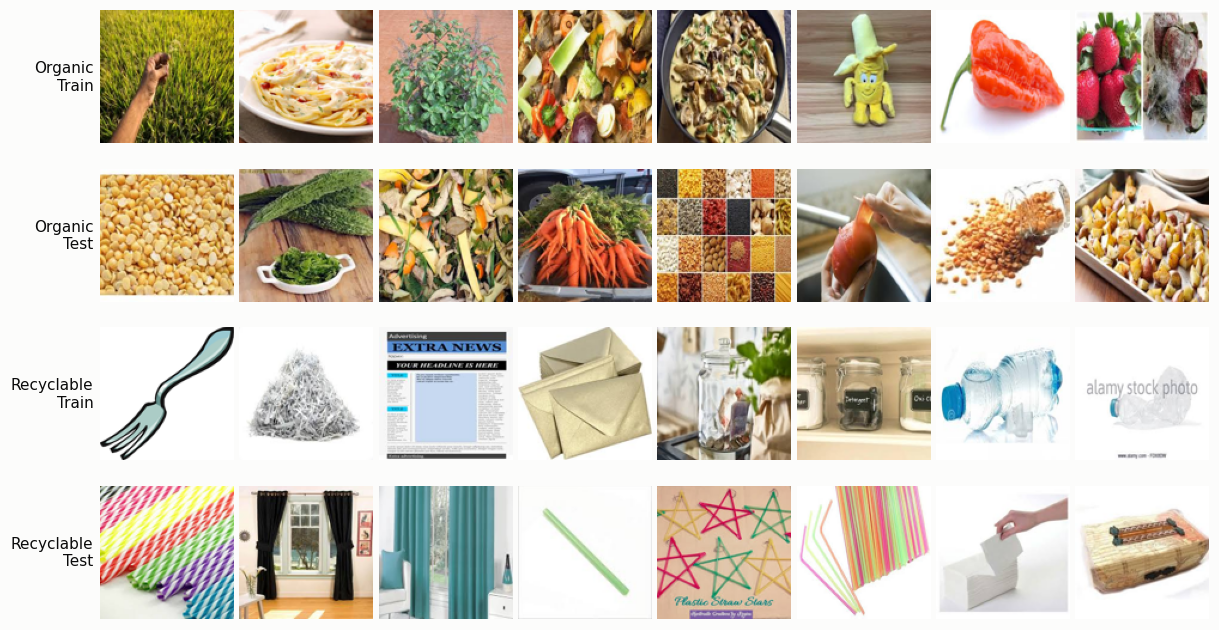

In [8]:
rng = np.random.default_rng(7)
rows = [(name, split) for name in CLASS_NAMES for split in ("TRAIN", "TEST")]
fig, axes = plt.subplots(len(rows), 8, figsize=(11, 5.9))
for r, (name, split) in enumerate(rows):
    sample = ok[(ok.label == name) & (ok.split == split)].sample(8, random_state=int(rng.integers(1e6)))
    for ax, path in zip(axes[r], sample.path):
        with Image.open(DATA_DIR / path) as im:
            ax.imshow(im.convert("RGB").resize((112, 112)))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for side in ax.spines.values():
            side.set_visible(False)
    axes[r, 0].set_ylabel(f"{name}\n{split.title()}", rotation=0, ha="right", va="center", color=ps.INK)
fig.tight_layout(pad=0.4)
ps.save(fig, "06_sample_images.png")